<a href="https://colab.research.google.com/github/bandapraneeth/Quantum-Hackathon/blob/main/question_47.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

!pip install -q qiskit qiskit-aer scikit-learn matplotlib pandas seaborn


In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time

from sklearn.datasets import make_blobs, load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    adjusted_rand_score,
    silhouette_score,
    davies_bouldin_score
)
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator

np.random.seed(42)

print("Libraries imported successfully")


Libraries imported successfully


In [ ]:

X_blobs, y_blobs = make_blobs(
    n_samples=120,
    n_features=10,
    centers=3,
    cluster_std=3.0,
    random_state=42
)

print("Dataset shape:", X_blobs.shape)
print("Classes:", np.unique(y_blobs))


Dataset shape: (120, 10)
Classes: [0 1 2]


In [ ]:

iris = load_iris()

X_iris = iris.data
y_iris = iris.target

print("Dataset shape:", X_iris.shape)
print("Features:", iris.feature_names)
print("Classes:", iris.target_names)


Dataset shape: (150, 4)
Features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Classes: ['setosa' 'versicolor' 'virginica']


In [ ]:

scaler_blobs = StandardScaler()
X_blobs_scaled = scaler_blobs.fit_transform(X_blobs)

scaler_iris = StandardScaler()
X_iris_scaled = scaler_iris.fit_transform(X_iris)

print("Scaling completed")


Scaling completed


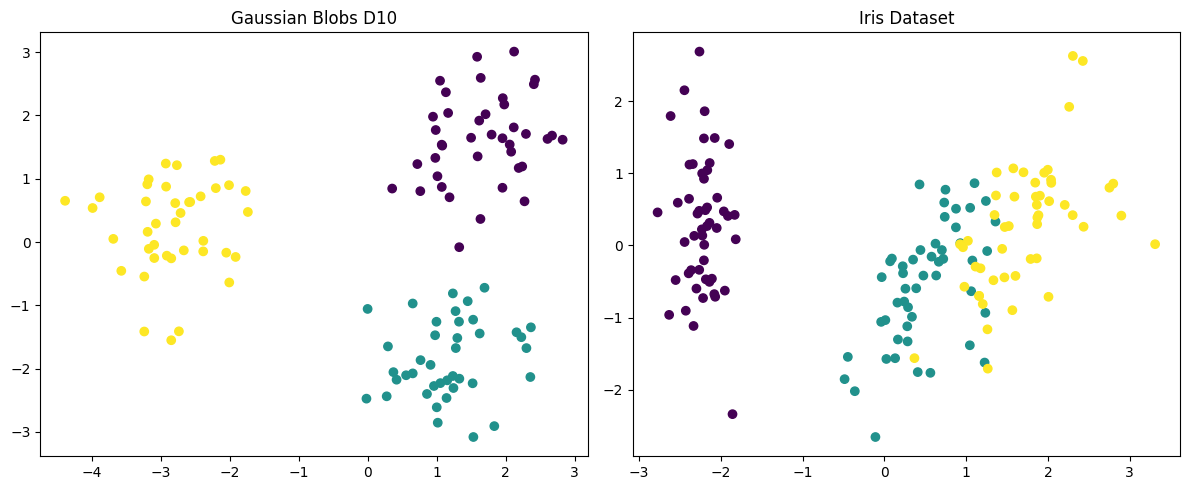

In [ ]:

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

pca_blobs = PCA(n_components=2)
blobs_2d = pca_blobs.fit_transform(X_blobs_scaled)

axes[0].scatter(
    blobs_2d[:, 0], blobs_2d[:, 1],
    c=y_blobs, cmap="viridis"
)
axes[0].set_title("Gaussian Blobs D10")

pca_iris = PCA(n_components=2)
iris_2d = pca_iris.fit_transform(X_iris_scaled)

axes[1].scatter(
    iris_2d[:, 0], iris_2d[:, 1],
    c=y_iris, cmap="viridis"
)
axes[1].set_title("Iris Dataset")

plt.tight_layout()
plt.show()


In [ ]:

simulator = AerSimulator()

SHOTS = 256

print("Quantum simulator initialized")
print("Shots:", SHOTS)


Quantum simulator initialized
Shots: 256


In [ ]:

def amplitude_encode(vector, n_qubits):
    vector = np.asarray(vector, dtype=float)

    dimension = 2 ** n_qubits

    padded = np.zeros(dimension)
    padded[:len(vector)] = vector

    norm = np.linalg.norm(padded)

    if norm == 0:
        padded[0] = 1.0
    else:
        padded = padded / norm

    return padded


In [ ]:

def quantum_swap_distance(x, c, shots=SHOTS):

    n_qubits = int(np.ceil(np.log2(len(x))))

    x_state = amplitude_encode(x, n_qubits)
    c_state = amplitude_encode(c, n_qubits)

    qc = QuantumCircuit(2 * n_qubits + 1, 1)

    ancilla = 0
    reg_x = list(range(1, n_qubits + 1))
    reg_c = list(range(n_qubits + 1, 2 * n_qubits + 1))

    # Prepare ancilla
    qc.h(ancilla)

    # Amplitude encoding
    qc.initialize(x_state, reg_x)
    qc.initialize(c_state, reg_c)

    # Controlled-SWAP operations
    for i in range(n_qubits):
        qc.cswap(ancilla, reg_x[i], reg_c[i])

    # Measurement
    qc.h(ancilla)
    qc.measure(ancilla, 0)

    compiled = transpile(qc, simulator)

    result = simulator.run(
        compiled,
        shots=shots
    ).result()

    counts = result.get_counts()

    p0 = counts.get("0", 0) / shots

    fidelity = np.clip(2 * p0 - 1, 0, 1)

    distance = np.sqrt(1 - fidelity)

    return distance, qc


In [ ]:


%pip install pylatexenc



In [ ]:


print("Quantum distance:", distance)
print("Qubits:", circuit.num_qubits)
print("Circuit depth:", circuit.depth())

# Display circuit without Matplotlib
print(circuit.draw(output="text"))


Quantum distance: 0.5659615711335886
Qubits: 5
Circuit depth: 5
                             ┌───┐                              ┌───┐┌─┐
q_0: ────────────────────────┤ H ├─────────────────────────■──■─┤ H ├┤M├
      ┌──────────────────────┴───┴──────────────────────┐  │  │ └───┘└╥┘
q_1: ─┤0                                                ├──X──┼───────╫─
      │  Initialize(-0.38845,0.43948,-0.57802,-0.56733) │  │  │       ║ 
q_2: ─┤1                                                ├──┼──X───────╫─
     ┌┴─────────────────────────────────────────────────┴┐ │  │       ║ 
q_3: ┤0                                                  ├─X──┼───────╫─
     │  Initialize(-0.51899,-0.059926,-0.60853,-0.59728) │    │       ║ 
q_4: ┤1                                                  ├────X───────╫─
     └───────────────────────────────────────────────────┘            ║ 
c: 1/═════════════════════════════════════════════════════════════════╩═
                                                            

In [ ]:


import sys
print(sys.executable)

import pylatexenc
print(pylatexenc.__version__)



/usr/bin/python3
2.11


In [ ]:

def quantum_kmeans(X, k=3, max_iter=5, shots=SHOTS):

    start_time = time.time()

    n_samples = len(X)

    # Initialize centroids randomly from data
    rng = np.random.default_rng(42)
    indices = rng.choice(n_samples, k, replace=False)

    centroids = X[indices].copy()

    labels = np.zeros(n_samples, dtype=int)

    circuit_evaluations = 0
    total_circuit_depth = 0
    total_qubits = 0

    for iteration in range(max_iter):

        new_labels = []

        # Assignment step
        for x in X:

            distances = []

            for centroid in centroids:

                distance, circuit = quantum_swap_distance(
                    x, centroid, shots
                )

                distances.append(distance)

                circuit_evaluations += 1
                total_circuit_depth += circuit.depth()
                total_qubits = circuit.num_qubits

            new_labels.append(np.argmin(distances))

        new_labels = np.array(new_labels)

        # Update step
        new_centroids = centroids.copy()

        for cluster in range(k):

            cluster_points = X[new_labels == cluster]

            if len(cluster_points) > 0:
                new_centroids[cluster] = cluster_points.mean(axis=0)

        # Convergence check
        if np.array_equal(labels, new_labels):
            centroids = new_centroids
            labels = new_labels
            break

        labels = new_labels
        centroids = new_centroids

    training_time = time.time() - start_time

    average_depth = (
        total_circuit_depth / circuit_evaluations
        if circuit_evaluations else 0
    )

    results = {
        "training_time": training_time,
        "circuit_evaluations": circuit_evaluations,
        "qubits": total_qubits,
        "average_depth": average_depth,
        "shots": shots,
        "iterations": iteration + 1
    }

    return labels, centroids, results


In [ ]:


q_labels_blobs, q_centroids_blobs, q_cost_blobs = quantum_kmeans(
    X_blobs_scaled,
    k=3,
    max_iter=2,
    shots=64
)

print("Gaussian Blobs quantum clustering completed")
print(q_cost_blobs)



Gaussian Blobs quantum clustering completed
{'training_time': 117.93937397003174, 'circuit_evaluations': 720, 'qubits': 9, 'average_depth': 7.0, 'shots': 64, 'iterations': 2}


In [ ]:

q_labels_iris, q_centroids_iris, q_cost_iris = quantum_kmeans(
    X_iris_scaled,
    k=3,
    max_iter=2,
    shots=64
)

print("Iris quantum clustering completed")
print(q_cost_iris)


Iris quantum clustering completed
{'training_time': 142.39794874191284, 'circuit_evaluations': 900, 'qubits': 5, 'average_depth': 5.0, 'shots': 64, 'iterations': 2}


In [ ]:

def evaluate_clustering(X, predicted_labels, actual_labels):

    ari = adjusted_rand_score(actual_labels, predicted_labels)
    silhouette = silhouette_score(X, predicted_labels)
    db_index = davies_bouldin_score(X, predicted_labels)

    return {
        "ARI": ari,
        "Silhouette": silhouette,
        "Davies-Bouldin": db_index
    }


In [ ]:

blobs_metrics = evaluate_clustering(
    X_blobs_scaled, q_labels_blobs, y_blobs
)

iris_metrics = evaluate_clustering(
    X_iris_scaled, q_labels_iris, y_iris
)

print("Gaussian Blobs D10:", blobs_metrics)
print("Iris:", iris_metrics)


Gaussian Blobs D10: {'ARI': 0.4737514248321864, 'Silhouette': np.float64(0.16860195199987546), 'Davies-Bouldin': np.float64(1.897222358327231)}
Iris: {'ARI': 0.11136265074142301, 'Silhouette': np.float64(0.0622344533455489), 'Davies-Bouldin': np.float64(3.355965740556281)}


In [ ]:

start = time.time()

classical_blobs = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
).fit_predict(X_blobs_scaled)

classical_blobs_time = time.time() - start

start = time.time()

classical_iris = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
).fit_predict(X_iris_scaled)

classical_iris_time = time.time() - start

print("Classical Blobs time:", classical_blobs_time)
print("Classical Iris time:", classical_iris_time)


Classical Blobs time: 0.11466073989868164
Classical Iris time: 0.027865886688232422


In [ ]:

comparison = pd.DataFrame({
    "Dataset": ["Gaussian Blobs D10", "Iris"],

    "Quantum ARI": [
        adjusted_rand_score(y_blobs, q_labels_blobs),
        adjusted_rand_score(y_iris, q_labels_iris)
    ],

    "Classical ARI": [
        adjusted_rand_score(y_blobs, classical_blobs),
        adjusted_rand_score(y_iris, classical_iris)
    ],

    "Quantum Time (s)": [
        q_cost_blobs["training_time"],
        q_cost_iris["training_time"]
    ],

    "Classical Time (s)": [
        classical_blobs_time,
        classical_iris_time
    ]
})

display(comparison.round(4))


,Dataset,Quantum ARI,Classical ARI,Quantum Time (s),Classical Time (s)
0,Gaussian Blobs D10,0.4738,1.0000,117.9394,0.1147
1,Iris,0.1114,0.6201,142.3979,0.0279


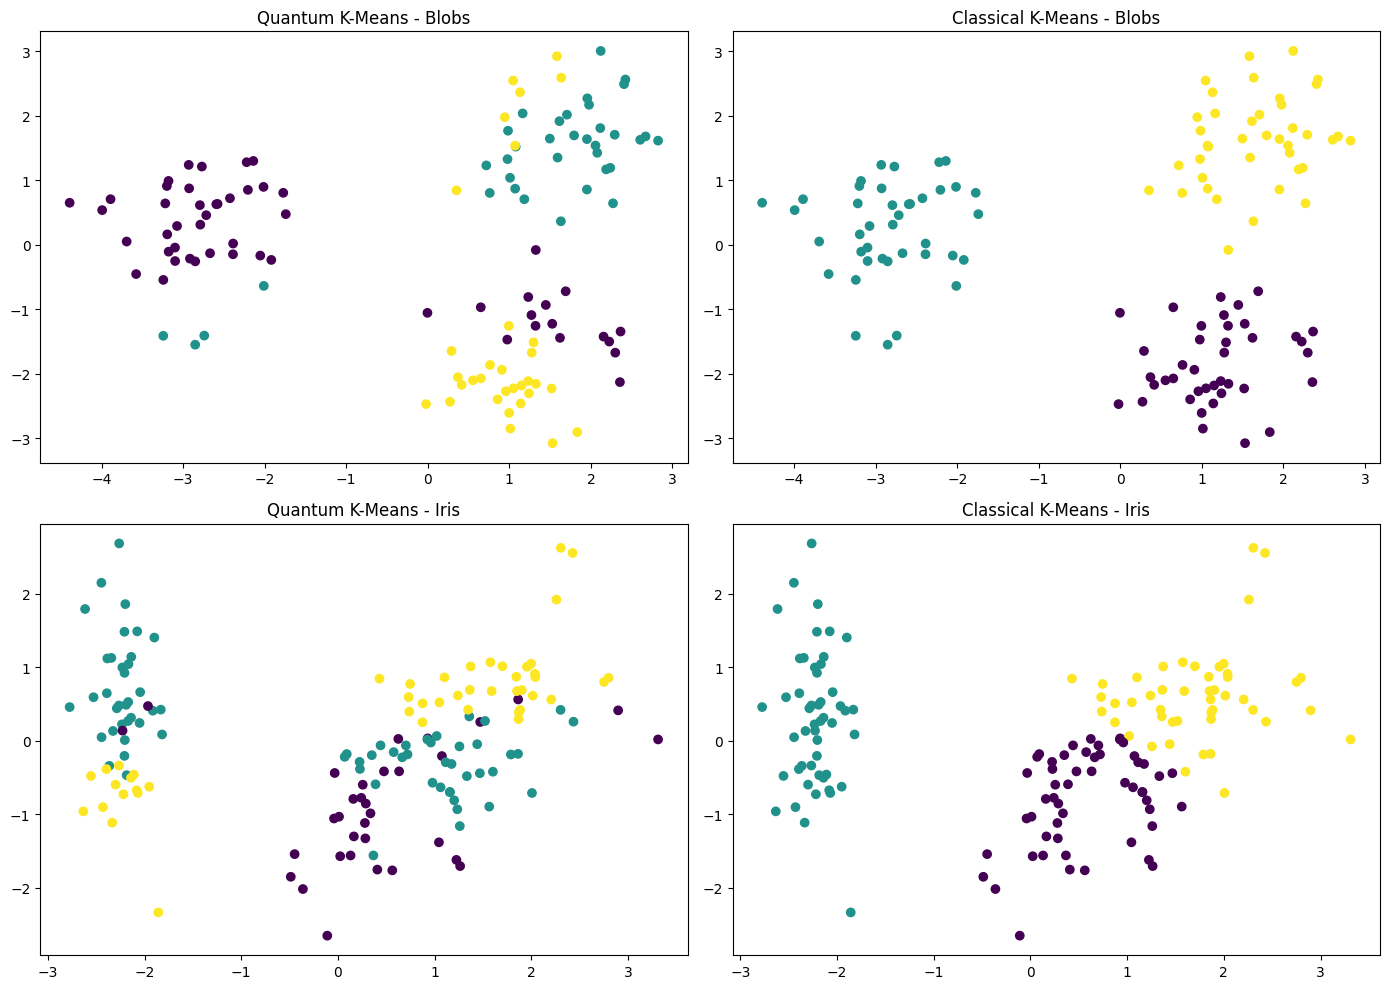

In [ ]:

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes[0, 0].scatter(
    blobs_2d[:, 0], blobs_2d[:, 1],
    c=q_labels_blobs, cmap="viridis"
)
axes[0, 0].set_title("Quantum K-Means - Blobs")

axes[0, 1].scatter(
    blobs_2d[:, 0], blobs_2d[:, 1],
    c=classical_blobs, cmap="viridis"
)
axes[0, 1].set_title("Classical K-Means - Blobs")

axes[1, 0].scatter(
    iris_2d[:, 0], iris_2d[:, 1],
    c=q_labels_iris, cmap="viridis"
)
axes[1, 0].set_title("Quantum K-Means - Iris")

axes[1, 1].scatter(
    iris_2d[:, 0], iris_2d[:, 1],
    c=classical_iris, cmap="viridis"
)
axes[1, 1].set_title("Classical K-Means - Iris")

plt.tight_layout()
plt.show()


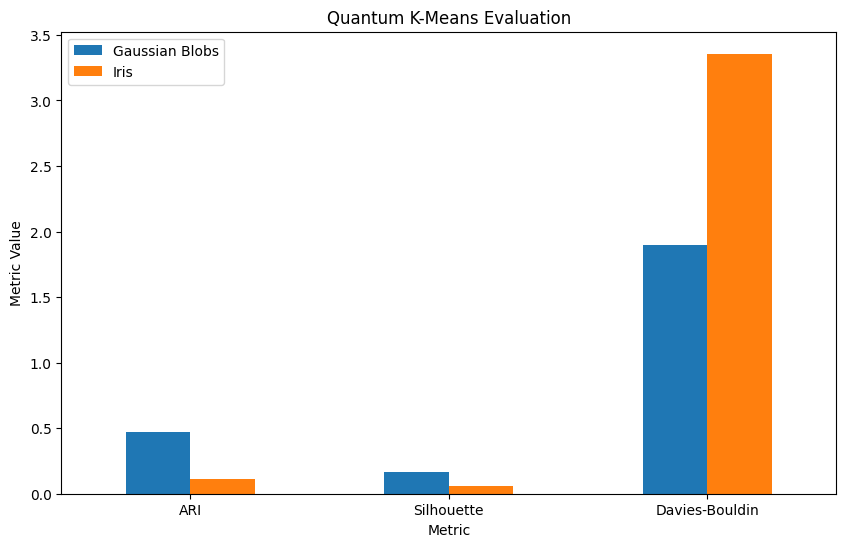

In [ ]:

metrics_df = pd.DataFrame({
    "Metric": ["ARI", "Silhouette", "Davies-Bouldin"],

    "Gaussian Blobs": [
        blobs_metrics["ARI"],
        blobs_metrics["Silhouette"],
        blobs_metrics["Davies-Bouldin"]
    ],

    "Iris": [
        iris_metrics["ARI"],
        iris_metrics["Silhouette"],
        iris_metrics["Davies-Bouldin"]
    ]
})

metrics_df.set_index("Metric").plot(
    kind="bar", figsize=(10, 6)
)

plt.title("Quantum K-Means Evaluation")
plt.ylabel("Metric Value")
plt.xticks(rotation=0)
plt.show()


In [ ]:

quantum_cost = pd.DataFrame({
    "Parameter": [
        "Qubits",
        "Circuit Depth",
        "Shots",
        "Circuit Evaluations",
        "Training Time (s)",
        "Iterations"
    ],

    "Gaussian Blobs D10": [
        q_cost_blobs["qubits"],
        q_cost_blobs["average_depth"],
        q_cost_blobs["shots"],
        q_cost_blobs["circuit_evaluations"],
        q_cost_blobs["training_time"],
        q_cost_blobs["iterations"]
    ],

    "Iris": [
        q_cost_iris["qubits"],
        q_cost_iris["average_depth"],
        q_cost_iris["shots"],
        q_cost_iris["circuit_evaluations"],
        q_cost_iris["training_time"],
        q_cost_iris["iterations"]
    ]
})

display(quantum_cost.round(3))


,Parameter,Gaussian Blobs D10,Iris
0,Qubits,9.000,5.000
1,Circuit Depth,7.000,5.000
2,Shots,64.000,64.000
3,Circuit Evaluations,720.000,900.000
4,Training Time (s),117.939,142.398
5,Iterations,2.000,2.000


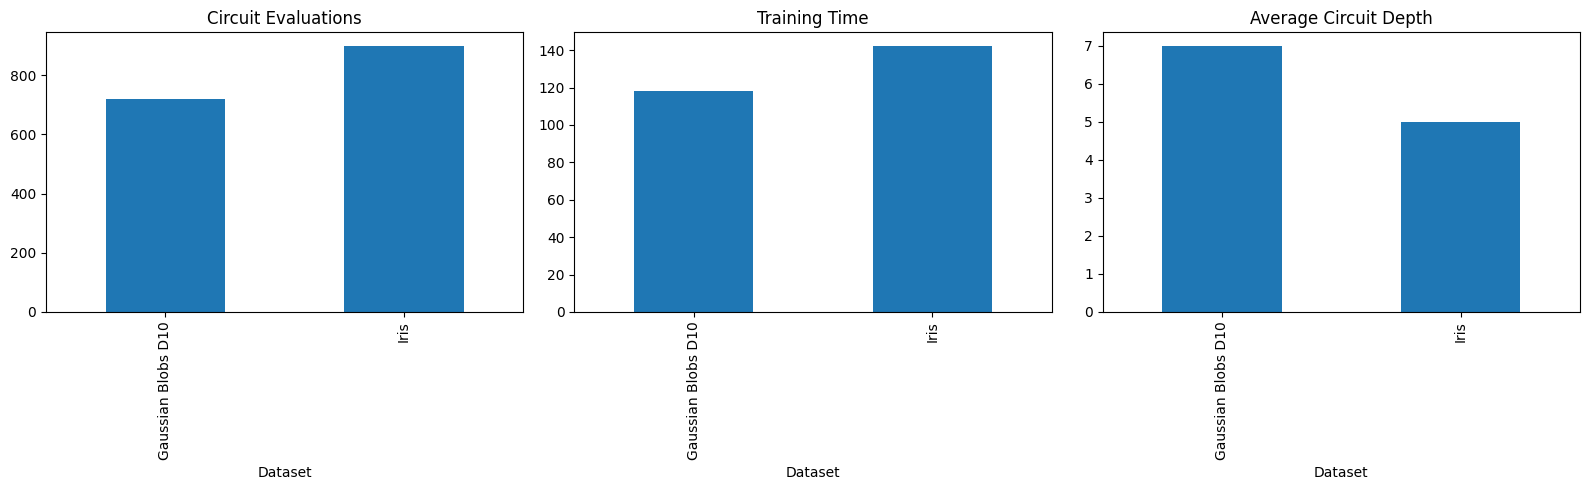

In [ ]:

cost_df = pd.DataFrame({
    "Dataset": ["Gaussian Blobs D10", "Iris"],

    "Circuit Evaluations": [
        q_cost_blobs["circuit_evaluations"],
        q_cost_iris["circuit_evaluations"]
    ],

    "Training Time": [
        q_cost_blobs["training_time"],
        q_cost_iris["training_time"]
    ],

    "Circuit Depth": [
        q_cost_blobs["average_depth"],
        q_cost_iris["average_depth"]
    ]
})

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

cost_df.plot(
    x="Dataset", y="Circuit Evaluations",
    kind="bar", ax=axes[0], legend=False
)
axes[0].set_title("Circuit Evaluations")

cost_df.plot(
    x="Dataset", y="Training Time",
    kind="bar", ax=axes[1], legend=False
)
axes[1].set_title("Training Time")

cost_df.plot(
    x="Dataset", y="Circuit Depth",
    kind="bar", ax=axes[2], legend=False
)
axes[2].set_title("Average Circuit Depth")

plt.tight_layout()
plt.show()


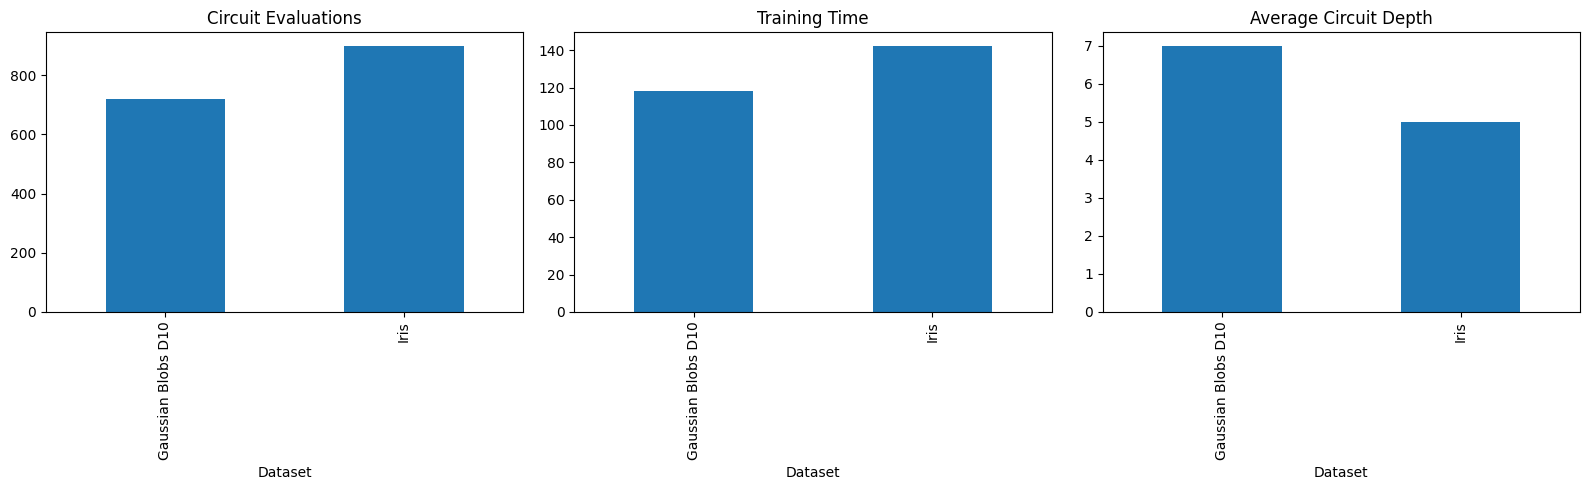

In [ ]:

cost_df = pd.DataFrame({
    "Dataset": ["Gaussian Blobs D10", "Iris"],

    "Circuit Evaluations": [
        q_cost_blobs["circuit_evaluations"],
        q_cost_iris["circuit_evaluations"]
    ],

    "Training Time": [
        q_cost_blobs["training_time"],
        q_cost_iris["training_time"]
    ],

    "Circuit Depth": [
        q_cost_blobs["average_depth"],
        q_cost_iris["average_depth"]
    ]
})

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

cost_df.plot(
    x="Dataset", y="Circuit Evaluations",
    kind="bar", ax=axes[0], legend=False
)
axes[0].set_title("Circuit Evaluations")

cost_df.plot(
    x="Dataset", y="Training Time",
    kind="bar", ax=axes[1], legend=False
)
axes[1].set_title("Training Time")

cost_df.plot(
    x="Dataset", y="Circuit Depth",
    kind="bar", ax=axes[2], legend=False
)
axes[2].set_title("Average Circuit Depth")

plt.tight_layout()
plt.show()
